In [15]:
#utils.py
import matplotlib.pyplot as plt
import random
from typing import List, Tuple
import math

def read_dataset(filename: str) -> List[Tuple[float, float]]:
    """
    Reads a .tsp file and extracts city coordinates.

    Args:
        filename (str): Name of the file (without path or extension).

    Returns:
        List[Tuple[float, float]]: List of city coordinates as (x, y) tuples.
    """
    with open(filename, 'r') as f:
        cities: List[Tuple[float, float]] = []
        for line in f:
            parts = line.split()
            if len(parts) == 3 and ":" not in parts:
                cities.append((float(parts[1]), float(parts[2])))
    return cities


def create_distance_matrix(cities: List[Tuple[float, float]]) -> List[List[float]]:
    """
    Builds an N×N matrix of pairwise Euclidean distances.

    Args:
        cities (List[Tuple[float, float]]): List of city coordinates.

    Returns:
        List[List[float]]: Distance matrix where element [i][j] is the distance from city i to city j.
    """
    matrix: List[List[float]] = []
    for i in range(len(cities)):
        row: List[float] = []
        for j in range(len(cities)):
            if i == j:
                row.append(0.0)
            else:
                x1, y1 = cities[i]
                x2, y2 = cities[j]
                dist = math.sqrt((x1 - x2) ** 2 + (y1 - y2) ** 2)
                row.append(dist)
        matrix.append(row)
    return matrix


def calculate_route_distance(route: List[int], distance_matrix: List[List[float]]) -> float:
    """
    Sums distances along the closed tour defined by `route`.

    Args:
        route (List[int]): A permutation representing a tour.
        distance_matrix (List[List[float]]): Precomputed pairwise distance matrix.

    Returns:
        float: Total distance of the closed tour.
    """
    total = 0.0
    n = len(route)
    for i in range(n):
        current = route[i]
        next = route[(i + 1) % n] 
        total += distance_matrix[current][next]
    return total


def fitness(route: List[int], distance_matrix: List[List[float]]) -> float:
    """
    Defines fitness as the inverse of the total route distance.

    Args:
        route (List[int]): A permutation representing a tour.
        distance_matrix (List[List[float]]): Precomputed pairwise distance matrix.

    Returns:
        float: Fitness value, higher is better.
    """
    d = calculate_route_distance(route, distance_matrix)
    return 1 / d if d != 0 else float('inf')


def generate_initial_population(num_individuals: int, num_cities: int) -> List[List[int]]:
    """
    Generates `num_individuals` random tours over `num_cities` cities.

    Args:
        num_individuals (int): Number of individuals in the population.
        num_cities (int): Number of cities in each tour.

    Returns:
        List[List[int]]: Initial population, a list of random permutations.
    """
    population = []
    base = list(range(num_cities))
    for _ in range(num_individuals):
        ind = base[:]
        random.shuffle(ind)
        population.append(ind)
    return population



def plot_route(cities, route=None):
    plt.figure(figsize=(10, 6))
    
    if route is not None:
        for i in range(len(route)):
            start = cities[route[i]]
            end   = cities[route[(i + 1) % len(route)]]
            plt.plot([start[0], end[0]], [start[1], end[1]], 'r-')

        
        start_node = cities[route[0]]
        end_node   = cities[route[-1]]
        plt.scatter(*start_node, c='blue', s=150, marker='*', label='Start')
        # plt.text(start_node[0] + 0.1, start_node[1] + 0.02, "Start", fontsize=9, color='green')
        
        plt.scatter(*end_node, c='red', s=150, marker='X', label='End')
        # plt.text(end_node[0] + 0.1, end_node[1] + 0.02, "End", fontsize=9, color='red')

   
    xs = [pt[0] for pt in cities]
    ys = [pt[1] for pt in cities]
    plt.scatter(xs, ys, c='blue', marker='o')
    for i, (x, y) in enumerate(cities):
        plt.text(x + 0.02, y + 0.02, str(i), fontsize=9, color='black')

    plt.title("2D Map of Points")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.grid(True)
    plt.legend()
    plt.show()

In [ ]:
#genetic.py
import random
from typing import List, Callable, Tuple


class GeneticAlgorithm:
    def __init__(
        self,
        population: List[List[int]],
        fitness_func: Callable[[List[int]], float],
        num_generations: int = 100,
        mutation_rate: float = 0.05,
        crossover_rate: float = 0.8,
        selection_strategy: str = 'tournament',  # 'tournament', 'roulette', 'rank'
        crossover_strategy: str = 'uniform',  # 'one_point', 'two_point', 'uniform'
        mutation_strategy: str = 'swap',        # 'swap', 'inversion', 'scramble'
        tournament_size: int = 3,
    ) -> None:
        """
        Initialize the genetic algorithm with population and configuration parameters.

        Args:
            population (List[List[int]]): Initial population of individuals.
            fitness_func (Callable[[List[int]], float]): Function to evaluate the fitness of an individual.
            num_generations (int): Number of generations to run the algorithm.
            mutation_rate (float): Probability of mutation for each individual.
            crossover_rate (float): Probability of crossover between pairs.
            selection_strategy (str): Selection method ('tournament', 'roulette', or 'rank').
            crossover_strategy (str): Crossover method ('one_point', 'two_point', or 'uniform').
            mutation_strategy (str): Mutation method ('swap', 'inversion', or 'scramble').
            tournament_size (int): Size of the tournament in tournament selection.
        """
        self.population: List[List[int]] = population
        self.fitness_func: Callable[[List[int]], float] = fitness_func
        self.num_generations: int = num_generations
        self.mutation_rate: float = mutation_rate
        self.crossover_rate: float = crossover_rate
        self.selection_strategy: str = selection_strategy
        self.crossover_strategy: str = crossover_strategy
        self.mutation_strategy: str = mutation_strategy
        self.tournament_size: int = tournament_size

        # History tracking
        self.best_fitness_history: List[float] = []
        self.best_distance_history: List[float] = []

    def evaluate_population(self) -> List[float]:
        """
        Evaluate the fitness of the current population.

        Returns:
            List[float]: A list containing the fitness value of each individual.
        """
        return [self.fitness_func(individual) for individual in self.population]

    def selection(self, fitnesses: List[float]) -> int:
        """
        Select an individual index based on the configured selection strategy.

        Args:
            fitnesses (List[float]): List of fitness values for the population.

        Returns:
            int: Index of the selected individual.
        """
        if self.selection_strategy == 'tournament':
            tournament = random.sample(range(len(fitnesses)), self.tournament_size)
            return max(tournament, key=lambda idx: fitnesses[idx])
        elif self.selection_strategy == 'roulette':
            total_fitness = sum(fitnesses)
            pick = random.uniform(0, total_fitness)
            current = 0
            for i, fitness in enumerate(fitnesses):
                current += fitness
                if current > pick:
                    return i
        elif self.selection_strategy == 'rank':
            sorted_indices = sorted(range(len(fitnesses)), key=lambda idx: fitnesses[idx])
            ranks = [i + 1 for i in range(len(fitnesses))]
            total_rank = sum(ranks)
            pick = random.uniform(0, total_rank)
            current = 0
            for idx in sorted_indices:
                current += ranks[idx]
                if current > pick:
                    return idx
        else:
            raise ValueError("Unknown selection strategy")

    def crossover(self, parent1: List[int], parent2: List[int]) -> List[int]:
        """
        Perform permutation-preserving crossover between two parents.

        Args:
            parent1 (List[int]): First parent individual.
            parent2 (List[int]): Second parent individual.

        Returns:
            List[int]: Offspring individual produced by crossover.
        """
        if self.crossover_strategy == 'one_point':
            point = random.randint(1, len(parent1) - 1)
            child = parent1[:point] + [gene for gene in parent2 if gene not in parent1[:point]]
        elif self.crossover_strategy == 'two_point':
            point1, point2 = sorted(random.sample(range(len(parent1)), 2))
            middle = parent1[point1:point2]
            child = (
                [gene for gene in parent2 if gene not in middle] +
                middle +
                [gene for gene in parent2 if gene not in middle]
            )
        elif self.crossover_strategy == 'uniform':
            child = []
            for gene1, gene2 in zip(parent1, parent2):
                child.append(gene1 if random.random() < 0.5 else gene2)
            child = list(dict.fromkeys(child)) 
            missing_genes = [gene for gene in parent1 if gene not in child]
            child.extend(missing_genes)
        else:
            raise ValueError("Unknown crossover strategy")
        return child

    def mutation(self, individual: List[int]) -> List[int]:
        """
        Apply mutation to an individual using the configured mutation strategy.

        Args:
            individual (List[int]): Individual to mutate.

        Returns:
            List[int]: Mutated individual.
        """
        if random.random() > self.mutation_rate:
            return individual

        if self.mutation_strategy == 'swap':
            idx1, idx2 = random.sample(range(len(individual)), 2)
            individual[idx1], individual[idx2] = individual[idx2], individual[idx1]
        elif self.mutation_strategy == 'inversion':
            idx1, idx2 = sorted(random.sample(range(len(individual)), 2))
            individual[idx1:idx2] = reversed(individual[idx1:idx2])
        elif self.mutation_strategy == 'scramble':
            idx1, idx2 = sorted(random.sample(range(len(individual)), 2))
            subset = individual[idx1:idx2]
            random.shuffle(subset)
            individual[idx1:idx2] = subset
        else:
            raise ValueError("Unknown mutation strategy")
        return individual

    def run(self) -> Tuple[List[int], float, List[float], List[float]]:
        """
        Run the genetic algorithm for the configured number of generations.

        Returns:
            Tuple containing:
                - List[int]: The best solution found.
                - float: Fitness of the best solution.
                - List[float]: History of best fitness values.
                - List[float]: History of best distance values.
        """
        for generation in range(self.num_generations):
            fitnesses = self.evaluate_population()
            new_population = []

            for _ in range(len(self.population) // 2):
                parent1_idx = self.selection(fitnesses)
                parent2_idx = self.selection(fitnesses)
                parent1 = self.population[parent1_idx]
                parent2 = self.population[parent2_idx]

                if random.random() < self.crossover_rate:
                    child1 = self.crossover(parent1, parent2)
                    child2 = self.crossover(parent2, parent1)
                else:
                    child1, child2 = parent1[:], parent2[:]

                child1 = self.mutation(child1)
                child2 = self.mutation(child2)

                new_population.extend([child1, child2])

            self.population = new_population[:len(self.population)]

            best_fitness = max(fitnesses)
            best_individual = self.population[fitnesses.index(best_fitness)]

            self.best_fitness_history.append(best_fitness)
            self.best_distance_history.append(1 / best_fitness if best_fitness != 0 else float('inf'))

        return best_individual, best_fitness, self.best_fitness_history, self.best_distance_history

Best route found: [34, 37, 33, 32, 36, 13, 9, 5, 3, 1, 0, 20, 28, 21, 23, 15, 11, 10, 26, 30, 35, 27, 8, 7, 6, 2, 4, 16, 17, 18, 12, 14, 19, 22, 24, 25, 29, 31] 38
Best fitness found: 9.183631037676356e-05
Best distance found: 10888.939199511005


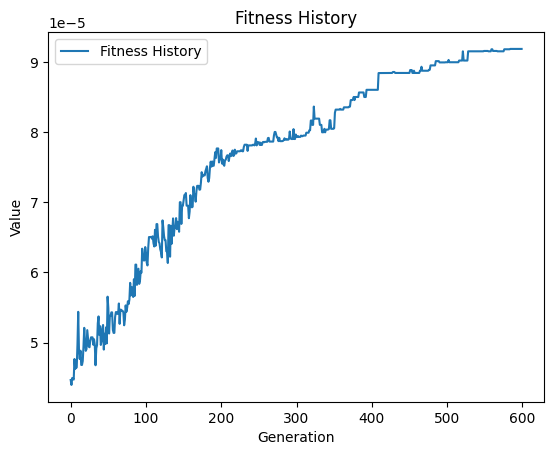

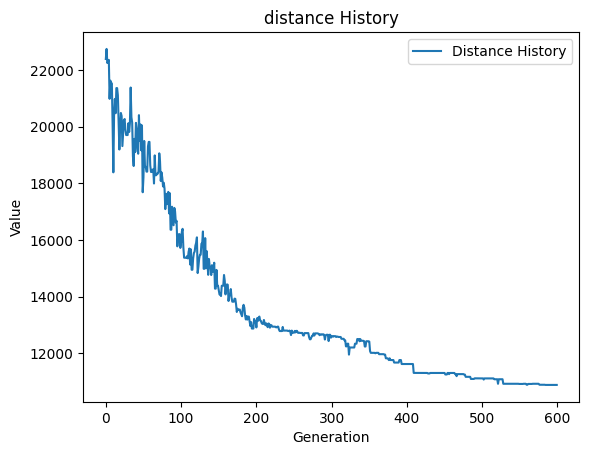

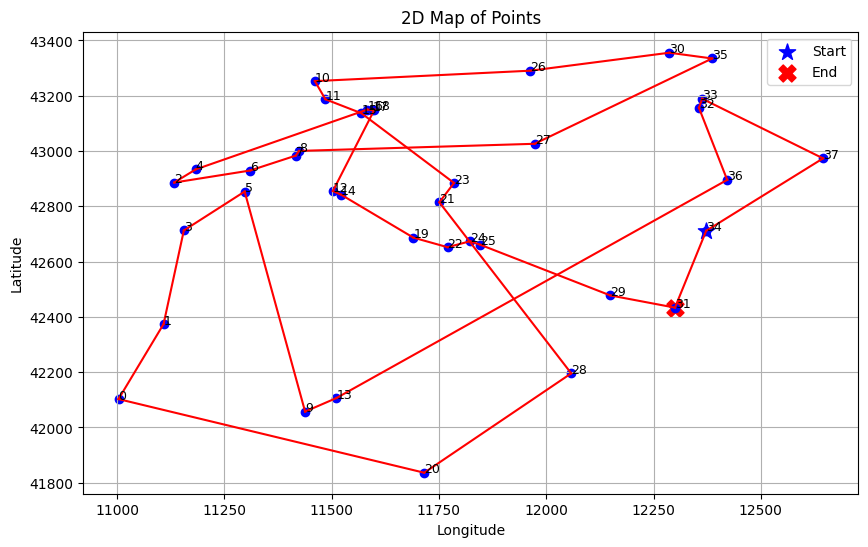

In [12]:
#main.py
# from genetic import GeneticAlgorithm
# from utils import generate_initial_population, create_distance_matrix, plot_route,read_dataset,fitness
import matplotlib.pyplot as plt


# TSP problem parameters
# CITY_COORDINATES = read_dataset("dj38.tsp")
CITY_COORDINATES = read_dataset("/work/dj38.tsp")

NUM_CITIES = len(CITY_COORDINATES)

def main():
    # Create a distance matrix based on city coordinates.
    distance_matrix = create_distance_matrix(CITY_COORDINATES)
    # Generate initial population of random routes.
    population = generate_initial_population(num_individuals=200, num_cities=NUM_CITIES)
    # Wrap the fitness function with the distance matrix.
    fitness_func = lambda route: fitness(route, distance_matrix)

    # Initialize the GeneticAlgorithm with all operators as in-class methods.
    ga = GeneticAlgorithm(population, fitness_func,
                          num_generations=600,
                          mutation_rate=0.1,
                          crossover_rate=0.9,
                          tournament_size=3)
    
    
    best_route, best_fitness,fitness_hist,distance_hist = ga.run()
    print("Best route found:", best_route,len(best_route))
    print("Best fitness found:", best_fitness)
    print("Best distance found:", 1/best_fitness)
    plt.plot(fitness_hist, label='Fitness History')
    plt.xlabel('Generation')
    plt.ylabel('Value')
    plt.title('Fitness History')
    plt.legend()
    plt.show()

    plt.plot(distance_hist, label='Distance History')
    plt.xlabel('Generation')
    plt.ylabel('Value')
    plt.title('distance History')
    plt.legend()
    plt.show()
    plot_route(CITY_COORDINATES, best_route)

if __name__ == '__main__':
    main()

<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=0bf2b0a9-bb3e-4fb9-aed6-433be1aa8eee' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>